### <b>4강 막대·산점도·히스토그램 - bar · scatter · hist</b>

* 범주끼리 크기를 비교할 때는 <b>막대 그래프</b>(<b>ax.bar</b>·<b>ax.barh</b>)를 그린다. 메뉴별 총판매량, 전공별 학생 수와 평균 공부 시간을 막대로 옮긴다.
* 두 수치의 관계는 <b>산점도</b>(<b>ax.scatter</b>)로 점을 찍어 본다. 공부 시간과 시험 점수, 기온과 에이드 판매량을 비교한다.
* 값이 어디에 몰려 있는지는 <b>히스토그램</b>(<b>ax.hist</b>)으로 구간을 나눠 세어 본다. 수면 시간과 SNS 사용 시간의 분포, 이상치를 확인한다.

* 첫 코드 셀은 매 시간 실행하는 <b>설정 셀</b>이다. 1강에서 정한 그대로다.

In [1]:
# keep
# 설명: 설정 셀은 출력이 없다. 아무것도 나오지 않는 것이 정상이다.
# 설명: 이 셀을 건너뛰면 뒤 그래프의 한글이 □로 나온다. □가 보이면 이 셀부터 확인하게 한다.
# 설명: pandas도 여기서 불러온다. 다음 셀의 pd가 없다고 나오면 이 셀을 실행하지 않은 것이다.
import platform
import pandas as pd
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
else:
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

* 오늘은 두 파일을 모두 쓴다. 2강과 같은 방법으로 읽는다.
  * <b>students</b>: 학생 300명의 생활 습관 설문(가상), 학생 1명 = 1행
  * <b>cafe</b>: 캠퍼스 카페 365일 판매(가상), 하루 = 1행. date 열은 날짜로 읽는다.

In [2]:
# keep
# 설명: ../는 노트북이 있는 폴더의 한 칸 위다. data 폴더가 04_기본그래프 폴더와 나란히 있어야 읽힌다.
# 설명: FileNotFoundError가 나오면 코드가 아니라 폴더 위치부터 본다.
# 설명: 출력 (300, 12) (365, 14)를 함께 확인한다. 이 숫자가 같으면 뒤 그래프도 같은 모양으로 나온다.
students = pd.read_csv('../data/students.csv')
cafe = pd.read_csv('../data/cafe_sales.csv', parse_dates=['date'])
print(students.shape, cafe.shape)

(300, 12) (365, 14)


#### <b>1) 메뉴별 총판매량 막대</b>

* 1년 동안 메뉴마다 몇 잔이 팔렸는지 비교한다. 먼저 그래프에 넣을 표를 만든다.
  * <b>cafe[['americano', 'latte', 'ade', 'tea']]</b>: 메뉴 4개 열만 고른다.
  * <b>sum()</b>: 열마다 값을 모두 더한다. 결과는 메뉴 이름이 index, 합계가 values인 <b>Series</b>다.

In [3]:
# 설명: 실행 전에 1년 동안 가장 많이 팔린 메뉴가 무엇일지 짐작하게 한다.
# 설명: 출력에서 americano 40866과 tea 9770을 짚는다. 왼쪽 이름이 index, 오른쪽 숫자가 values다.
# 설명: 다음 셀에서 이 두 부분을 그대로 x와 y에 넣는다고 연결한다.
menu_total = cafe[['americano', 'latte', 'ade', 'tea']].sum()
menu_total

americano    40866
latte        22611
ade          20523
tea           9770
dtype: int64

* <b>ax.bar(x, y)</b>: x의 범주마다 y 높이의 세로 막대를 그린다.
  * 3강의 선 그래프와 같이 index를 x, values를 y로 넣는다. 그리는 함수만 plot에서 bar로 바뀐다.
  * 제목과 y축 이름(단위)도 3강처럼 붙인다.

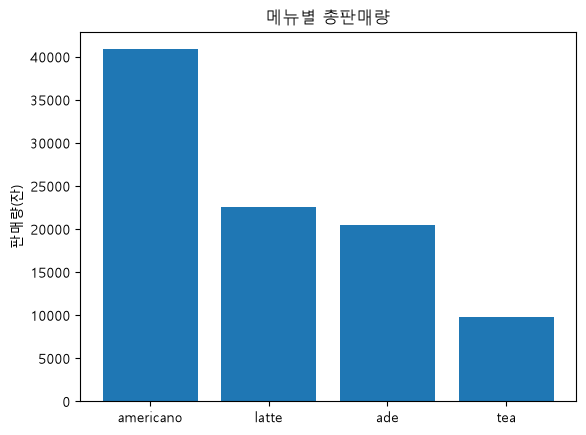

In [4]:
# 설명: 실행 전에 3강 코드와 나란히 떠올리게 한다. 달라진 줄은 ax.bar 한 줄이다.
# 설명: 실행 후 y축 맨 아래 0을 손으로 짚는다. 뒤에 나오는 '막대는 0에서 시작' 설명의 근거다.
# 설명: x축 이름이 영어인 것은 열 이름이 영어이기 때문이다. 큰 순서로 놓인 것도 열 순서가 그럴 뿐, 정렬한 것이 아니다.
# 설명: ax.bar(menu_total)처럼 하나만 넣으면 height가 없다는 TypeError가 난다. index와 values 둘 다 넘긴다.
fig, ax = plt.subplots()
ax.bar(menu_total.index, menu_total.values)
ax.set_title('메뉴별 총판매량')
ax.set_ylabel('판매량(잔)')
plt.show()

* 그래프에서 읽을 것
  * 아메리카노(40,866잔)가 가장 높고, 차(9,770잔)가 가장 낮다. 아메리카노 막대가 차 막대의 약 4배 길이다.
  * 라떼(22,611잔)와 에이드(20,523잔)는 높이가 비슷하다.
* 막대의 y축은 저절로 <b>0</b>에서 시작한다. 막대는 길이로 크기를 비교하므로 0에서 시작해야 "4배 길면 4배 많다"가 맞다.
  * 선 그래프는 흐름을 보는 그래프라 y축이 0에서 시작하지 않아도 된다(3강의 월별 평균 그래프는 110 근처에서 시작했다).

#### <b>2) 전공별 학생 수 가로 막대와 정렬</b>

* 2강의 <b>value_counts()</b>로 전공마다 학생 수를 센다. 결과는 많은 순으로 정렬된 Series다.
  * 자연과학과 인문은 둘 다 55명으로 같다.

In [5]:
# 설명: 앞의 sum은 값을 더했고 value_counts는 같은 값이 몇 번 나오는지 센다. 출력 끝 Name: count가 그 표시다.
# 설명: 출력 맨 위 공학 80, 맨 아래 예체능 40을 짚는다. 다섯 값을 더하면 300명이다.
# 설명: 많은 순으로 정렬된 이 표를 다음 셀에서 그대로 가로 막대에 넘긴다.
major_count = students['major'].value_counts()
major_count

major
공학      80
사회과학    70
자연과학    55
인문      55
예체능     40
Name: count, dtype: int64

* <b>ax.barh(y, 너비)</b>: 가로 막대를 그린다. 범주 이름이 세로축에 놓이고, 막대가 오른쪽으로 뻗는다.
  * 범주 이름이 길거나 범주가 많을 때 글자가 겹치지 않아 읽기 쉽다.
  * 가로 막대에서는 값이 x축에 있으므로 단위는 <b>set_xlabel</b>에 쓴다.

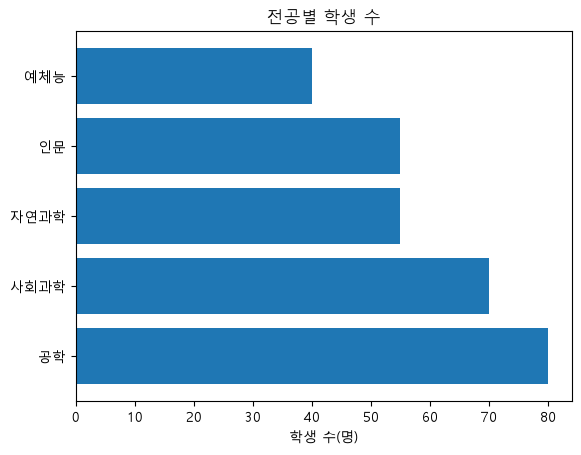

In [6]:
# 설명: 실행 전에 표 맨 위의 공학이 그래프 어디에 나올지 짐작하게 한다.
# 설명: 실행 후 공학이 맨 아래, 예체능이 맨 위인 것을 짚는다. 코드가 틀린 것이 아니다.
# 설명: x축 눈금이 0에서 80까지다. 세로 막대와 달리 값을 가로로 읽는다.
# 설명: 위아래 순서는 아직 고치지 않는다. 이유와 해결은 다음 셀에서 본다.
fig, ax = plt.subplots()
ax.barh(major_count.index, major_count.values)
ax.set_title('전공별 학생 수')
ax.set_xlabel('학생 수(명)')
plt.show()

* 가장 많은 공학이 맨 아래에 있다. barh는 첫 번째 값을 <b>맨 아래</b>에 그리고 위로 쌓아 올리기 때문이다.
* 큰 막대를 맨 위에 두려면 작은 값부터 오도록 정렬해서 넘긴다.
  * <b>sort_values()</b>: 값을 작은 것부터 정렬한다(2강의 ascending=False를 빼면 오름차순).
  * 정렬해서 그리면 막대 길이 순서와 위아래 순서가 같아져 순위가 한눈에 읽힌다.

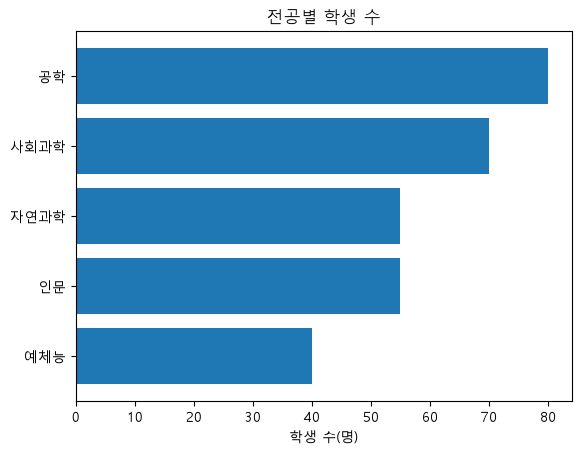

In [7]:
# 설명: 그리는 코드는 앞 셀과 같고 넘기는 표만 major_count_sorted로 바뀐다.
# 설명: sort_values는 정렬한 새 Series를 돌려준다. 그래서 새 이름에 담고, major_count는 그대로 남는다.
# 설명: 실행 후 앞 그래프와 번갈아 본다. 공학이 맨 위로 올라왔다.
# 설명: 자연과학과 인문의 위아래도 앞 그래프와 바뀌어 있다. 둘 다 55명이라 생긴 일이다.
major_count_sorted = major_count.sort_values()

fig, ax = plt.subplots()
ax.barh(major_count_sorted.index, major_count_sorted.values)
ax.set_title('전공별 학생 수')
ax.set_xlabel('학생 수(명)')
plt.show()

* 그래프에서 읽을 것
  * 공학(80명)이 맨 위에서 가장 길고, 예체능(40명)이 맨 아래에서 가장 짧다.
  * 자연과학과 인문은 55명으로 막대 길이가 같다. 같은 값끼리는 순서가 정해져 있지 않으니 순위로 읽지 않는다.

#### <b>3) 전공별 평균 공부 시간 막대(groupby 결과)</b>

* 2강에서 만든 전공별 평균 공부 시간 표를 다시 만든다. 큰 값부터 정렬된 Series다.

In [8]:
# 설명: 한 줄이 길다. 왼쪽부터 끊어 읽는다. 전공으로 묶고, study_hours를 고르고, 평균을 내고, 반올림하고, 정렬한다.
# 설명: 출력 맨 위 공학 18.16, 맨 아래 예체능 6.28을 짚는다.
# 설명: 계산은 복잡해 보여도 결과는 앞의 표들과 같은 모양이다. 왼쪽 index, 오른쪽 values다.
study_by_major = students.groupby('major')['study_hours'].mean().round(2).sort_values(ascending=False)
study_by_major

major
공학      18.16
자연과학    13.62
사회과학    11.59
인문       9.42
예체능      6.28
Name: study_hours, dtype: float64

* groupby 결과도 index(전공)와 values(평균)가 있으므로 1)과 똑같이 <b>ax.bar</b>로 그린다.
  * 큰 값부터 정렬한 표라서 막대가 왼쪽부터 높은 순으로 놓인다.

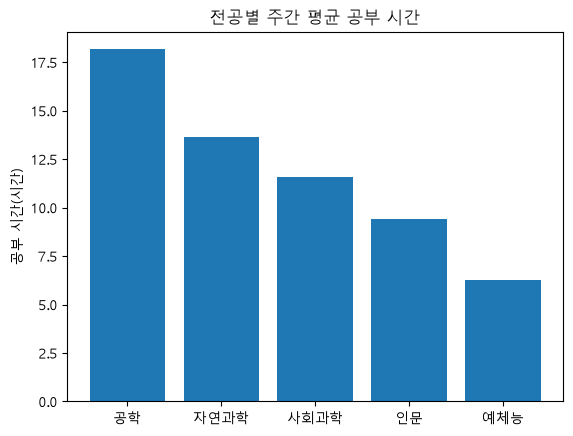

In [9]:
# 설명: 코드는 메뉴 막대와 같은 구조다. 표 이름, 제목, y축 이름만 다르다.
# 설명: 실행 후 y축이 0.0에서 시작하는 것을 다시 확인한다. 값이 소수여도 막대는 0부터다.
# 설명: 막대 하나는 전공 평균 하나다. 같은 전공 안에서 학생마다 다른 모습은 보이지 않는다.
# 설명: 그래서 다음 셀부터 학생 한 명 한 명을 점으로 찍는다.
fig, ax = plt.subplots()
ax.bar(study_by_major.index, study_by_major.values)
ax.set_title('전공별 주간 평균 공부 시간')
ax.set_ylabel('공부 시간(시간)')
plt.show()

* 그래프에서 읽을 것
  * 공학(18.16시간)이 가장 높고 예체능(6.28시간)이 가장 낮다. 공학이 예체능의 약 3배다.
  * 막대가 왼쪽부터 공학 → 자연과학 → 사회과학 → 인문 → 예체능 순으로 낮아진다.
* 막대 그래프는 개수(value_counts)든 평균(groupby)이든 <b>범주 하나에 값 하나</b>인 표를 그린다.

#### <b>4) 공부 시간과 시험 점수 산점도</b>

* <b>산점도</b>: 두 수치 열을 x와 y로 놓고 한 행을 점 하나로 찍는 그래프다. 여기서는 학생 한 명이 점 하나다.
* <b>ax.scatter(x, y)</b>: x와 y 자리에 점을 찍는다. plot과 달리 점을 선으로 잇지 않는다.
  * x에 주간 공부 시간, y에 시험 점수를 넣는다. 점 300개가 찍힌다.

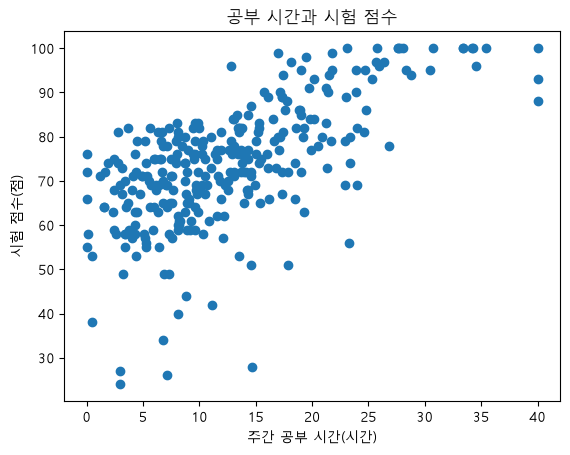

In [10]:
# 설명: 막대와 달리 표를 따로 만들지 않는다. students의 두 열을 바로 넣는다.
# 설명: x와 y는 같은 표에서 가져와야 개수가 맞는다. students와 cafe를 섞으면 x and y must be the same size 오류가 난다.
# 설명: 실행 후 x축 끝 40시간의 점과 맨 아래 24점 근처의 점을 짚는다. 값의 범위가 그대로 축이 된다.
fig, ax = plt.subplots()
ax.scatter(students['study_hours'], students['exam_score'])
ax.set_title('공부 시간과 시험 점수')
ax.set_xlabel('주간 공부 시간(시간)')
ax.set_ylabel('시험 점수(점)')
plt.show()

* 그래프에서 읽을 것
  * 점들이 왼쪽 아래에서 오른쪽 위로 비스듬히 퍼져 있다. 공부 시간이 길수록 점수가 높은 학생이 많다.
  * 한 줄로 딱 붙어 있지는 않다. 같은 공부 시간이어도 점수가 넓게 흩어져 있다.
* 0~20시간 근처는 점이 빽빽하게 겹쳐 몇 개가 모여 있는지 보이지 않는다.
  * <b>s</b>: 점 크기. 기본값은 36이다. 작게 하면 겹침이 줄어든다.
  * <b>alpha</b>: 투명도. 0(투명)~1(불투명). 0.5로 하면 점이 겹친 곳이 더 진하게 보인다.

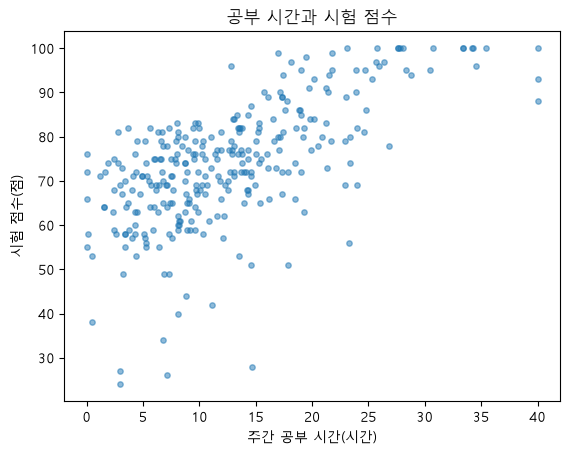

In [11]:
# 설명: 앞 셀과 다른 것은 s=15, alpha=0.5 두 인자뿐이다. 나머지 줄은 그대로다.
# 설명: 실행 전에 말해 둔다. 점이 줄어드는 것이 아니라 작고 흐려질 뿐이고, 여전히 300개다.
# 설명: 실행 후 앞 그래프와 번갈아 보며 5~20시간 덩어리를 비교한다.
# 설명: 맨 위 100점 줄도 짚는다. 100점이 13명이라 점이 진하게 겹친 자리가 있다.
fig, ax = plt.subplots()
ax.scatter(students['study_hours'], students['exam_score'], s=15, alpha=0.5)
ax.set_title('공부 시간과 시험 점수')
ax.set_xlabel('주간 공부 시간(시간)')
ax.set_ylabel('시험 점수(점)')
plt.show()

* 점이 작고 투명해져, 진하게 겹친 곳(공부 5~20시간, 점수 60~90점 근처)에 학생이 많이 모여 있는 것이 보인다.
* 오른쪽 끝 40시간 근처의 점들은 점수가 88~100점으로 높다.

#### <b>5) 기온과 에이드 판매량 산점도</b>

* 카페 데이터에서 하루가 점 하나다. x에 그날 평균 기온, y에 에이드 판매 잔 수를 놓는다.

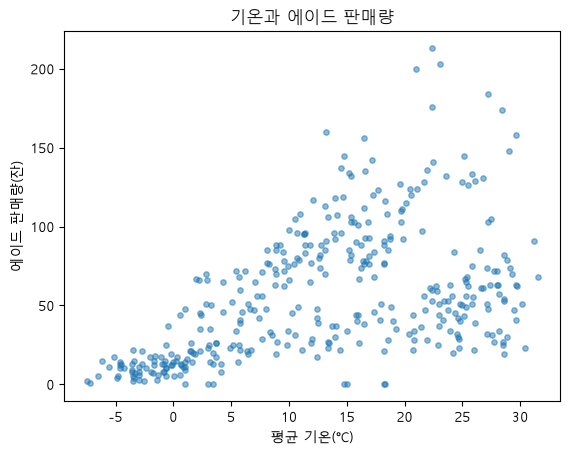

In [12]:
# 설명: 표가 students에서 cafe로 바뀐다. 이제 점 하나는 학생이 아니라 하루이고, 점은 365개다.
# 설명: s=15, alpha=0.5는 앞에서 본 값을 처음부터 넣는다.
# 설명: 실행 후 20°C를 넘으면 위 갈래의 점이 듬성해지는 것을 짚는다. 더운 7·8월이 방학이라 손님 자체가 적다.
# 설명: 바닥의 점 7개는 x가 1~18°C에 흩어져 있다. 휴무일에도 기온은 기록되어 있어 판매 0으로 찍힌 것이다.
fig, ax = plt.subplots()
ax.scatter(cafe['avg_temp'], cafe['ade'], s=15, alpha=0.5)
ax.set_title('기온과 에이드 판매량')
ax.set_xlabel('평균 기온(°C)')
ax.set_ylabel('에이드 판매량(잔)')
plt.show()

* 그래프에서 읽을 것
  * 기온이 오를수록 에이드가 많이 팔리는 쪽으로 점이 올라간다. 영하의 날은 많아야 40잔이 안 된다.
  * 10°C 무렵부터 점이 위아래 두 갈래로 벌어진다. 위 갈래는 손님이 많은 학기 평일, 아래 갈래는 손님이 적은 주말·방학이다(무리를 나눠 색으로 그리는 방법은 8강).
  * 맨 아래 0에 붙은 점 7개는 추석·설 휴무일이다.
* 비교로 기온과 <b>손님 수</b>를 찍어 본다. 관계가 약하면 어떤 모양인지 본다.

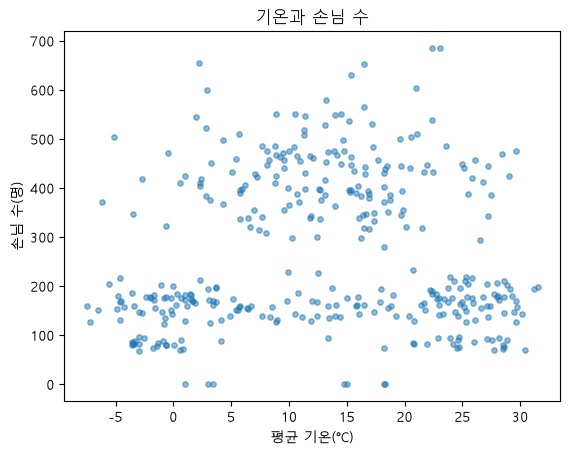

In [13]:
# 설명: 앞 셀에서 y만 ade에서 customers로 바꾼다. 실행 전에 더우면 손님도 늘지 예상을 묻는다.
# 설명: 실행 후 왼쪽 끝부터 오른쪽 끝까지 위 띠의 높이가 그대로인 것을 손으로 따라간다. 앞 그래프의 기울기와 비교한다.
# 설명: 평균으로는 학기 평일 413.4명, 학기 주말 151.2명, 방학 평일 173.5명이다. 그래서 띠가 위아래로 나뉜다.
# 설명: 관계의 방향과 강도를 숫자로 보는 상관계수는 8강에서 다룬다. 여기서는 모양으로만 읽는다.
fig, ax = plt.subplots()
ax.scatter(cafe['avg_temp'], cafe['customers'], s=15, alpha=0.5)
ax.set_title('기온과 손님 수')
ax.set_xlabel('평균 기온(°C)')
ax.set_ylabel('손님 수(명)')
plt.show()

* 기온이 바뀌어도 점들이 오르거나 내려가지 않는다. 기온과 손님 수는 관계가 거의 없다.
  * 점이 위(학기 평일)와 아래(주말·방학) 두 띠로 나뉘는 것은 기온이 아니라 학사 일정 때문이다.
* 산점도는 점들이 <b>기울어진 방향</b>으로 관계를 읽는다. 오른쪽 위로 올라가면 함께 늘고, 평평하게 퍼지면 관계가 약하다.

#### <b>6) 수면 시간 히스토그램과 bins 바꿔 보기</b>

* <b>분포</b>: 값들이 어느 범위에 얼마나 퍼져 있는지, 어디에 몰려 있는지의 모양이다.
* 2강에서 sleep_hours에 빈 값이 15개 있었다. 히스토그램을 그리기 전에 빈 값을 빼 둔다.
  * <b>Series.dropna()</b>: 빈 값(NaN)을 뺀 새 Series를 돌려준다. 2강의 dropna(subset=...)를 열 하나에 쓴 것이다.
  * <b>len()</b>으로 남은 개수를 확인한다. 300명 중 15명이 빠져 285명이다.
  * 이 버전의 ax.hist는 빈 값을 말없이 건너뛴다. 미리 빼고 개수를 확인해야 몇 명을 그린 그래프인지 안다.

In [14]:
# 설명: 빈 값을 뺀 열을 sleep에 담아 두는 이유는 뒤 히스토그램 네 장이 모두 이 변수를 쓰기 때문이다.
# 설명: 출력 285를 확인한다. 300이 나오면 dropna가 빠진 것이다.
# 설명: 이 셀을 건너뛰면 다음 셀에서 sleep이 없다는 NameError가 난다. 위에서부터 차례로 실행하게 한다.
sleep = students['sleep_hours'].dropna()
len(sleep)

285

* <b>ax.hist(값)</b>: 값의 범위를 같은 너비의 <b>구간(bin)</b>으로 나누고, 구간마다 값이 몇 개 들어가는지 세어 막대로 그린다.
  * 기본 구간 수는 10개다. x축은 수면 시간, y축은 그 구간에 든 학생 수다.
  * 막대 그래프는 x축이 범주(전공)지만, 히스토그램은 x축이 이어진 수치 구간이라 막대 사이에 틈이 없다.

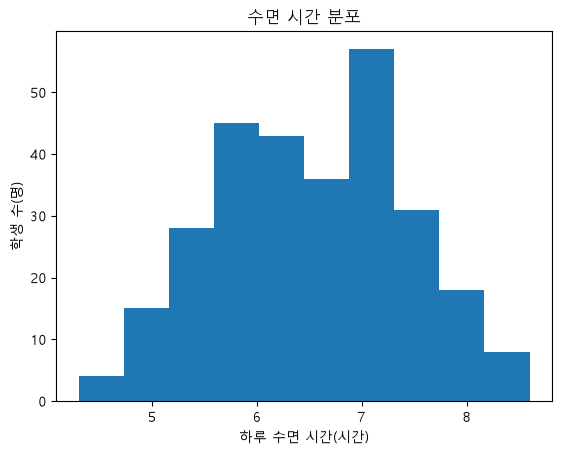

In [15]:
# 설명: 막대 그래프와 달리 미리 센 표를 만들지 않는다. 값 열을 넣으면 hist가 구간을 나누고 세어 준다.
# 설명: 실행 후 막대가 10개인 것을 함께 센다. x축은 4.3시간에서 8.6시간까지이고 구간 너비는 약 0.43시간이다.
# 설명: 57명 막대 바로 왼쪽 막대는 36명으로 낮다. 종 모양이 매끈하지 않은 것을 보여 주고 bins로 넘어간다.
fig, ax = plt.subplots()
ax.hist(sleep)
ax.set_title('수면 시간 분포')
ax.set_xlabel('하루 수면 시간(시간)')
ax.set_ylabel('학생 수(명)')
plt.show()

* 가운데(6~7시간대)가 높고 양 끝(4시간대, 8시간대)으로 갈수록 낮아지는 종 모양이다.
  * 가장 높은 막대는 6.88~7.31시간 구간으로 57명이다.
* <b>bins</b>: 구간 수를 정한다. 같은 데이터라도 bins에 따라 모양이 달라 보인다.
  * bins=5: 구간이 넓어 막대 5개로 뭉뚱그려진다. 큰 모양만 보인다.

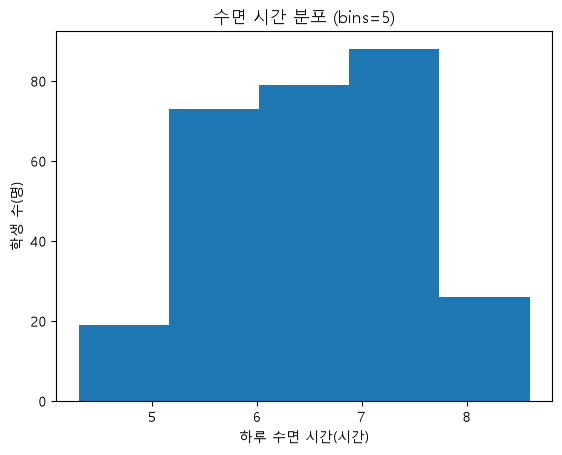

In [16]:
# 설명: 앞 셀과 다른 것은 bins=5와 제목뿐이다. 구간 너비가 약 0.86시간으로 두 배가 된다.
# 설명: 가장 높은 막대는 6.88~7.74시간 88명이다. 앞 그래프의 57명과 31명 두 막대가 하나로 합쳐진 것이다.
# 설명: 학생 수는 그대로 285명이다. 묶는 폭만 바뀌었다.
fig, ax = plt.subplots()
ax.hist(sleep, bins=5)
ax.set_title('수면 시간 분포 (bins=5)')
ax.set_xlabel('하루 수면 시간(시간)')
ax.set_ylabel('학생 수(명)')
plt.show()

* bins=20: 구간이 좁아져 막대가 촘촘해진다. 종 모양이 유지되면서 조금 더 자세히 보인다.

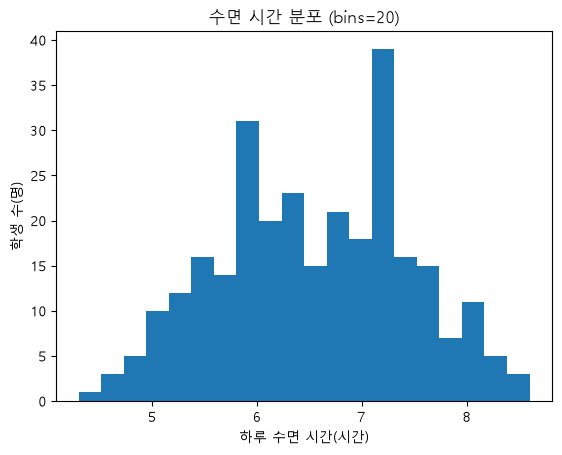

In [17]:
# 설명: 구간 너비는 약 0.22시간으로 기본의 절반이다. 막대마다 든 학생이 줄어 y축이 40까지로 낮아진다.
# 설명: 가장 높은 막대는 7.10~7.31시간 39명이다.
# 설명: 6시간 바로 아래의 31명 막대도 튀어나온다. 구간을 바꾸면 세부 모양이 달라진다는 예로 쓴다.
fig, ax = plt.subplots()
ax.hist(sleep, bins=20)
ax.set_title('수면 시간 분포 (bins=20)')
ax.set_xlabel('하루 수면 시간(시간)')
ax.set_ylabel('학생 수(명)')
plt.show()

* bins=50: 구간이 너무 좁아 중간중간 빈 구간이 생기고 막대가 들쭉날쭉하다.
  * 수면 시간은 6.5, 6.6처럼 0.1시간 단위로 적혀 있는데, 구간 너비(약 0.09시간)가 그보다 좁아 값이 하나도 안 들어가는 구간이 생긴다.
* bins는 너무 적으면 모양이 뭉개지고, 너무 많으면 잡음이 커진다. 몇 가지 값을 바꿔 보며 모양이 안정적으로 보이는 값을 고른다.

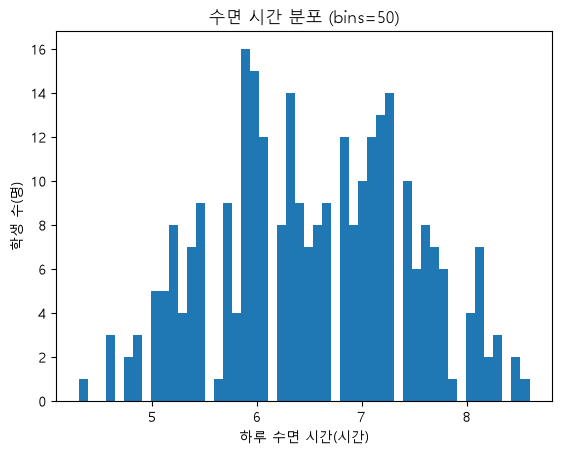

In [18]:
# 설명: 실행 전에 앞 세 장과 같은 데이터라는 것을 다시 말한다. 바뀐 것은 bins 값뿐이다.
# 설명: 실행 후 막대 사이 흰 틈을 짚는다. 범주 막대의 틈과 달리 이 틈은 그 구간에 학생이 0명이라는 뜻이다.
# 설명: 가장 높은 막대가 6시간 바로 아래 16명으로 옮겨 간다. 앞의 7시간대와 자리가 달라진 것을 비교한다.
fig, ax = plt.subplots()
ax.hist(sleep, bins=50)
ax.set_title('수면 시간 분포 (bins=50)')
ax.set_xlabel('하루 수면 시간(시간)')
ax.set_ylabel('학생 수(명)')
plt.show()

#### <b>7) SNS 사용 시간 히스토그램에서 이상치 찾기</b>

* sns_minutes도 빈 값 6개를 빼고 시작한다. 294명이 남는다.

In [19]:
# 설명: 수면에서 한 순서를 그대로 따른다. 빈 값을 빼고, 개수를 확인하고, 그린다.
# 설명: 출력 294를 확인한다. 수면의 285와 다른 것은 열마다 빈 값 수가 다르기 때문이다.
sns_min = students['sns_minutes'].dropna()
len(sns_min)

294

* 하루 SNS 사용 시간을 bins=20으로 그린다.

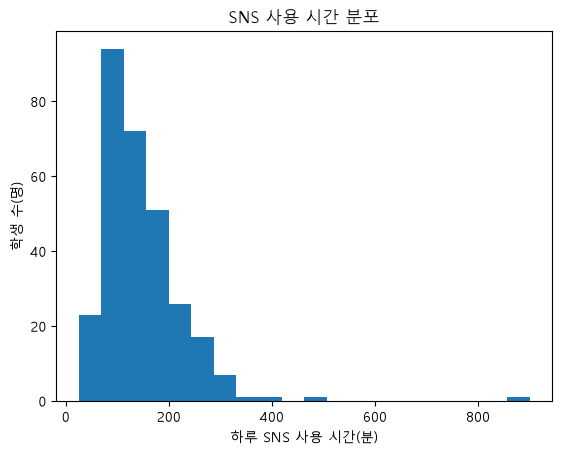

In [20]:
# 설명: 실행 전에 수면처럼 가운데가 높은 종 모양일지 묻는다.
# 설명: 실행 후 가장 높은 막대가 왼쪽 90명대이고 오른쪽 끝 막대는 높이가 1이라 잘 안 보인다. 화면을 키워 찾게 한다.
# 설명: 구간 너비는 약 44분이다. 900분을 뺀 그래프와 비교할 숫자이니 기억해 두게 한다.
# 설명: 400 근처와 480 근처의 낮은 막대도 짚어 둔다. 누구인지는 다음 셀에서 찾는다.
fig, ax = plt.subplots()
ax.hist(sns_min, bins=20)
ax.set_title('SNS 사용 시간 분포')
ax.set_xlabel('하루 SNS 사용 시간(분)')
ax.set_ylabel('학생 수(명)')
plt.show()

* 그래프에서 읽을 것
  * 대부분의 막대가 왼쪽(25~200분)에 몰려 있고, 오른쪽으로 갈수록 낮아지는 긴 꼬리 모양이다.
  * 오른쪽 끝 900분 근처에 높이 1짜리 막대가 홀로 떨어져 있다. 그 앞 약 510~850분 구간은 비어 있다.
  * 값 하나 때문에 x축이 900까지 늘어나, 나머지 막대가 왼쪽에 좁게 눌려 있다.
* 2강의 필터로 400분 이상인 학생을 찾아본다. 900분은 S026 한 명이고, 그다음은 480분이다.

In [21]:
# 설명: sns_min이 아니라 students에서 거른다. 학생 번호와 전공을 함께 보려면 표가 필요하다.
# 설명: 출력 3행을 읽는다. S026 900, S104 480, S130 410이다.
# 설명: 맨 왼쪽 25, 103, 129는 원래 표의 행 번호다. 걸러도 새로 매겨지지 않는다.
# 설명: S026은 수면도 4.3시간으로 전체 최저다. 입력 실수라고 바로 단정하지 않는다.
students[students['sns_minutes'] >= 400][['student_id', 'major', 'sns_minutes']]

,student_id,major,sns_minutes
25,S026,자연과학,900.0
103,S104,사회과학,480.0
129,S130,사회과학,410.0


* 900분(15시간)은 다른 값과 동떨어진 <b>이상치</b>다. 히스토그램에서는 홀로 떨어진 막대로 드러난다.
* 900분을 빼고 그리면 나머지 학생들의 분포가 넓게 펼쳐져 보인다.
  * <b>sns_min[sns_min < 900]</b>: 2강의 조건 필터를 Series에 쓴 것이다. 900분 미만만 남긴다.
  * 그래프를 보려고 잠시 뺀 것이다. 원래 데이터에서 지울지는 입력 실수인지 확인한 뒤 정한다.

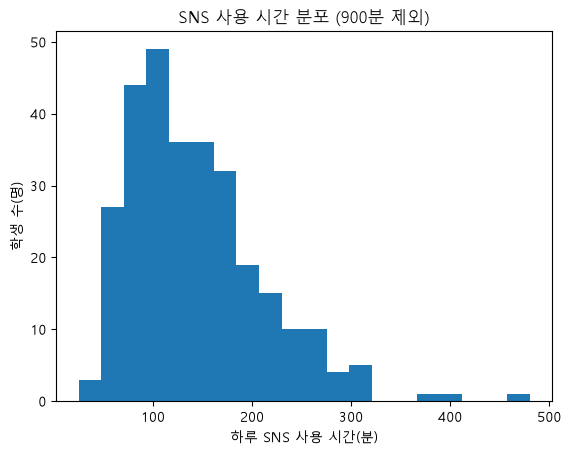

In [22]:
# 설명: 거른 결과를 변수에 담지 않고 hist에 바로 넘긴다. sns_min은 294명 그대로다.
# 설명: bins는 앞과 같은 20이지만 값의 끝이 480이 되어 구간 너비가 약 44분에서 약 23분으로 좁아진다.
# 설명: 그래서 가장 높은 막대가 50 근처로 낮아진다. 한 명을 뺐을 뿐이고, 좁아진 구간에 학생이 나뉜 것이다.
# 설명: 막대와 점이 모두 같은 파란색이고 그래프가 한 장씩 따로 나오는 불편은 5강에서 다룬다고 예고한다.
fig, ax = plt.subplots()
ax.hist(sns_min[sns_min < 900], bins=20)
ax.set_title('SNS 사용 시간 분포 (900분 제외)')
ax.set_xlabel('하루 SNS 사용 시간(분)')
ax.set_ylabel('학생 수(명)')
plt.show()

* x축이 480분까지로 줄어, 70~185분 근처에 가장 많이 몰려 있고 오른쪽으로 꼬리가 길게 늘어진 모양이 또렷해진다.
  * 오른쪽 끝의 작은 막대는 그다음으로 큰 480분이다.
* 오늘 그린 세 그래프를 정리하면 <b>비교는 막대(bar·barh), 관계는 점(scatter), 분포는 구간(hist)</b>이다.